# Best replicated variant — evaluation on `stories_10k.jsonl`

The model here is **"No Classifier"**: ChunkyBERT's architecture with the classification head
simplified to a bare `Linear` (no dropout). It was the top-scoring variant of the Table 10
ablation sweep, excluding the full ChunkyBERT itself:

| Variant | Val acc (1 epoch, Article-Bias-Prediction) |
|---|---|
| **No Classifier (this model)** | **82.36%** |
| No Transformers | 82.31% |
| Max Pool | 81.84% |
| No Attention | 81.43% |
| Full ChunkyBERT | 80.99% |
| No Chunking | 77.81% |
| Freeze BERT | 58.15% |

Retrained with weight saving under the same protocol (1 epoch, batch 16, AdamW `lr=2e-5`,
5,000-token documents in 512-token chunks) and scored **82.21%** — reproducing the sweep within noise.

Evaluated below on the 30,000 **labelled source articles** in `stories_10k.jsonl` (10,000 each from
left / centre / right outlets). The 10,000 generated `neutral` summaries carry no label, so they get
probabilities only, no confusion matrix.

In [1]:
import json, sys, math
import numpy as np, pandas as pd, torch
from pathlib import Path
from transformers import BertTokenizer
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)

ROOT = Path("/root/ANLP/ANLP-Project")
sys.path.insert(0, str(ROOT / "replication"))
from variants import VariantClassifier, TABLE10

WEIGHTS = ROOT / "models/no_classifier_1ep.pt"
DATA    = ROOT / "data/stories_10k.jsonl"
CLASSES = ["Left", "Centre", "Right"]
SLOT2ID = {"left": 0, "center": 1, "right": 2}
BATCH, MAX_LEN = 16, 5000

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Load the model

In [2]:
cfg = dict(TABLE10["No Classifier"])
print("config:", cfg)

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
model = VariantClassifier(num_classes=3, **cfg)
model.load_state_dict(torch.load(WEIGHTS, map_location="cpu", weights_only=True))
model.eval().to(device)
print(model.cfg)
print(f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters")

config: {'simple_head': True}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'backbone': 'bert', 'encoder': 'transformer', 'pooling': 'attention', 'chunk_agg': 'mean', 'chunking': True, 'freeze_backbone': False, 'simple_head': True}
117.6M parameters


## 2. Load the data

In [3]:
stories = [json.loads(l) for l in DATA.open(encoding="utf-8") if l.strip()]

src = pd.DataFrame([
    {"story_id": s["story_id"], "split": s.get("split"), "slot": slot,
     "label": SLOT2ID[slot], "publisher": s[slot]["publisher"], "text": s[slot]["body"]}
    for s in stories for slot in ("left", "center", "right")
])
summ = pd.DataFrame([{"story_id": s["story_id"], "text": s["neutral"]} for s in stories])
print(f"labelled source articles: {len(src)}   unlabelled neutral summaries: {len(summ)}")
src.label.value_counts().rename(index=dict(enumerate(CLASSES))).to_frame("articles")

labelled source articles: 30000   unlabelled neutral summaries: 10000


,articles
label,
Left,10000
Centre,10000
Right,10000


## 3. Score

In [4]:
@torch.no_grad()
def score(texts, batch=BATCH, tag=""):
    out = []
    for i in range(0, len(texts), batch):
        enc = tokenizer(texts[i:i+batch], return_tensors="pt", truncation=True,
                        max_length=MAX_LEN, padding=True)
        ids, mask = enc["input_ids"].to(device), enc["attention_mask"].to(device)
        with torch.autocast("cuda", enabled=device.type == "cuda"):
            logits = model(ids, mask, tokenizer)
        out.append(torch.softmax(logits.float(), dim=1).cpu())
        if (i // batch) % 200 == 0:
            print(f"  {tag} {i:>6}/{len(texts)}", flush=True)
    return torch.cat(out).numpy()

def attach(df, probs):
    df = df.copy()
    df[["p_left", "p_centre", "p_right"]] = probs
    df["pred_id"] = probs.argmax(1)
    df["pred"] = [CLASSES[i] for i in df.pred_id]
    df["confidence"] = probs.max(1)
    s = np.sort(probs, axis=1)
    df["margin"] = s[:, -1] - s[:, -2]
    df["entropy"] = -(probs * np.log(probs + 1e-12)).sum(1) / math.log(3)
    return df

src  = attach(src,  score(src.text.tolist(),  tag="sources"))
summ = attach(summ, score(summ.text.tolist(), tag="summaries"))
src.drop(columns="text").to_csv(ROOT / "evaluation/scores/best_variant_source_scores.csv", index=False)
summ.drop(columns="text").to_csv(ROOT / "evaluation/scores/best_variant_summary_scores.csv", index=False)
src[["story_id", "slot", "publisher", "p_left", "p_centre", "p_right", "pred", "confidence"]].head(12)

  sources      0/30000


  sources   3200/30000


  sources   6400/30000


  sources   9600/30000


  sources  12800/30000


...

  summaries      0/10000


  summaries   3200/10000


  summaries   6400/10000


  summaries   9600/10000


,story_id,slot,publisher,p_left,p_centre,p_right,pred,confidence
0,1000122,left,cnn,0.991992,0.002011,0.005997,Left,0.991992
1,1000122,center,hill,0.930180,0.009976,0.059843,Left,0.930180
2,1000122,right,breitbart,0.400412,0.061826,0.537762,Right,0.537762
3,1000196,left,nyt,0.825807,0.041376,0.132817,Left,0.825807
4,1000196,center,ap,0.000808,0.005168,0.994024,Right,0.994024
5,1000196,right,fox,0.021577,0.029035,0.949388,Right,0.949388
6,100020,left,dailykos,0.726070,0.029418,0.244513,Left,0.726070
7,100020,center,hill,0.382054,0.053582,0.564364,Right,0.564364
8,100020,right,breitbart,0.393660,0.007252,0.599088,Right,0.599088
9,1000204,left,nyt,0.825807,0.041376,0.132817,Left,0.825807


## 4. Confusion matrix — 30,000 labelled source articles

In [5]:
y_true, y_pred = src.label.values, src.pred_id.values
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
cm_df["total"] = cm_df.sum(1)
print(f"Overall accuracy: {(y_true == y_pred).mean():.4f}")
cm_df

Overall accuracy: 0.4040


/tmp/ipykernel_112745/538146299.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  cm_df["total"] = cm_df.sum(1)


,pred Left,pred Centre,pred Right,total
true Left,3354,1167,5479,10000
true Centre,2231,456,7313,10000
true Right,1028,662,8310,10000


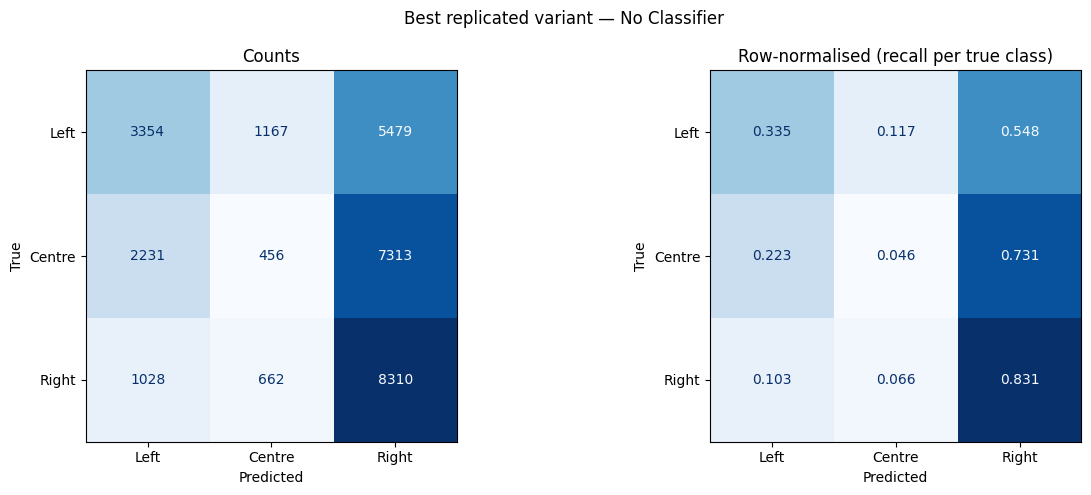

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Counts")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".3f")
ax[1].set_title("Row-normalised (recall per true class)")
for a in ax: a.set(xlabel="Predicted", ylabel="True")
plt.suptitle("Best replicated variant — No Classifier")
plt.tight_layout(); plt.show()

In [7]:
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
P = src[["p_left", "p_centre", "p_right"]].values
print(f"AUC-ROC (OvR, macro)   : {roc_auc_score(y_true, P, multi_class='ovr', average='macro'):.4f}")
print(f"AUC-ROC (OvR, weighted): {roc_auc_score(y_true, P, multi_class='ovr', average='weighted'):.4f}")

              precision    recall  f1-score   support

        Left     0.5072    0.3354    0.4038     10000
      Centre     0.1996    0.0456    0.0742     10000
       Right     0.3938    0.8310    0.5344     10000

    accuracy                         0.4040     30000
   macro avg     0.3668    0.4040    0.3375     30000
weighted avg     0.3668    0.4040    0.3375     30000

AUC-ROC (OvR, macro)   : 0.6126
AUC-ROC (OvR, weighted): 0.6126


### Mean predicted probability by true class

In [8]:
(src.groupby(src.label.map(dict(enumerate(CLASSES))))[["p_left", "p_centre", "p_right"]]
    .mean().reindex(CLASSES).rename_axis("true class").round(4))

,p_left,p_centre,p_right
true class,,,
Left,0.3503,0.1524,0.4973
Centre,0.2473,0.0934,0.6593
Right,0.1474,0.1006,0.7520


## 5. Accuracy by confidence and by publisher

In [9]:
bands = pd.cut(src.confidence, [0, .4, .5, .6, .7, .8, .9, 1.0], include_lowest=True)
(src.assign(correct=src.label == src.pred_id).groupby(bands, observed=False)
    .agg(articles=("correct", "size"), accuracy=("correct", "mean"))
    .assign(share=lambda t: (t.articles / len(src)).map("{:.1%}".format), accuracy=lambda t: t.accuracy.round(4)))

,articles,accuracy,share
confidence,,,
"(-0.001, 0.4]",121,0.2645,0.4%
"(0.4, 0.5]",1353,0.3067,4.5%
"(0.5, 0.6]",3411,0.3295,11.4%
"(0.6, 0.7]",3661,0.3261,12.2%
"(0.7, 0.8]",4143,0.3543,13.8%
"(0.8, 0.9]",5273,0.3994,17.6%
"(0.9, 1.0]",12038,0.4802,40.1%


In [10]:
(src.assign(correct=src.label == src.pred_id).groupby(["slot", "publisher"])
    .agg(articles=("correct", "size"), accuracy=("correct", "mean"))
    .sort_values(["slot", "accuracy"], ascending=[True, False]).round(4))

articles  accuracy
slot   publisher                    
center usatoday       2001    0.1319
       hill           6089    0.0256
       ap             1910    0.0188
left   cnn             863    0.7567
       nyt            2854    0.4121
       dailykos       2257    0.2654
       wpo            1199    0.2469
       hpo            2827    0.2229
right  wat            2814    0.9009
       breitbart      4644    0.8168
       fox            2542    0.7797

## 6. Comparison with the full ChunkyBERT

Same 30,000 articles, same protocol. ChunkyBERT's scores come from the earlier evaluation
(`source_article_scores.csv`, 5-epoch checkpoint).

In [11]:
try:
    prev = pd.read_csv(ROOT / "evaluation/scores/source_article_scores.csv")
    rows = []
    for name, d in [("ChunkyBERT (5 epochs)", prev), ("No Classifier (1 epoch)", src)]:
        acc = (d.label == d.pred_id).mean()
        rec = [ (d[d.label == i].pred_id == i).mean() for i in range(3) ]
        rows.append([name, round(acc, 4)] + [round(r, 4) for r in rec])
    print(pd.DataFrame(rows, columns=["model", "accuracy", "recall Left", "recall Centre", "recall Right"]
                      ).to_string(index=False))
except FileNotFoundError:
    print("previous ChunkyBERT scores not found")

                  model  accuracy  recall Left  recall Centre  recall Right
  ChunkyBERT (5 epochs)     0.443       0.4866         0.1324        0.7099
No Classifier (1 epoch)     0.404       0.3354         0.0456        0.8310


## 7. Neutral summaries (unlabelled — no confusion matrix possible)

In [12]:
dist = pd.DataFrame({
    "mean_prob":    summ[["p_left", "p_centre", "p_right"]].mean().values,
    "argmax_count": [(summ.pred == c).sum() for c in CLASSES],
}, index=CLASSES)
dist["argmax_share"] = (dist.argmax_count / len(summ)).map("{:.1%}".format)
dist.round(4)

,mean_prob,argmax_count,argmax_share
Left,0.2064,999,10.0%
Centre,0.0611,33,0.3%
Right,0.7326,8968,89.7%


## Notes

- Labels are **outlet-level**, inherited from the publisher rather than annotated per article, so an
  article counted wrong may simply be an off-median piece from that outlet.
- This model was trained for **one epoch** — the protocol under which it was selected as best in the
  ablation sweep. The ChunkyBERT comparison used a 5-epoch checkpoint, so that row has an advantage.
- Per-article probabilities: `best_variant_source_scores.csv`, `best_variant_summary_scores.csv`.